# Notebook 4: Final Test-Set Evaluation

Evaluate the fixed TF–IDF + Logistic Regression baseline and the selected fine-tuned DistilBERT model on the same held-out test set. This notebook does not train either model. The selected DistilBERT folder must already exist in Google Drive, and the fitted TF–IDF pipeline is uploaded if it is not already in the runtime.

Labels: `0 = non-clickbait`, `1 = clickbait`. The displayed probability is model confidence, not a verified measure of how misleading a headline is.


## 1. Install/import dependencies and mount Drive

In [1]:
%pip -q install transformers==4.50.3 scikit-learn joblib seaborn

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from google.colab import drive, files
from transformers import AutoTokenizer, AutoModelForSequenceClassification

drive.mount('/content/drive')


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Mounted at /content/drive


## 2. Set model/data paths
Change `BEST_MODEL_FOLDER` to the version selected from Notebook 3. The current top validation F1 was V3, so the default below points to `distilbert_v3_new`.

In [2]:
PROJECT_DIR = Path('/content/drive/MyDrive/clickbait_project')
BEST_MODEL_FOLDER = 'distilbert_v3_new'  # Change if you selected a different version
DISTILBERT_DIR = PROJECT_DIR / 'models' / BEST_MODEL_FOLDER
TEST_PATH = PROJECT_DIR / 'datasets' / 'headlines_test.csv'
TFIDF_LR_PATH = Path('/content/tfidf_lr.joblib')  # Upload to this Colab runtime if missing
RESULTS_DIR = PROJECT_DIR / 'results' / 'final_test'
MAX_LEN = 64

if not DISTILBERT_DIR.is_dir():
    raise FileNotFoundError(f'DistilBERT model folder not found: {DISTILBERT_DIR}. Save the selected model there from Notebook 3.')


## 3. Load the test data and model artifacts

In [3]:
if not TEST_PATH.exists():
    print(f'Upload {TEST_PATH.name} (or place it in {TEST_PATH.parent})')
    uploaded = files.upload()
    if TEST_PATH.name in uploaded:
        TEST_PATH.parent.mkdir(parents=True, exist_ok=True)
        TEST_PATH.write_bytes(uploaded[TEST_PATH.name])
    elif TEST_PATH.name in [Path(name).name for name in uploaded]:
        name = next(name for name in uploaded if Path(name).name == TEST_PATH.name)
        TEST_PATH.parent.mkdir(parents=True, exist_ok=True)
        TEST_PATH.write_bytes(uploaded[name])
if not TEST_PATH.exists():
    raise FileNotFoundError(f'Could not find {TEST_PATH.name}.')

if not TFIDF_LR_PATH.exists():
    print('Upload the fitted tfidf_lr.joblib pipeline from Notebook 2 results/tfidf_lr/')
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith('.joblib')]
    if len(candidates) != 1:
        raise ValueError('Upload exactly one .joblib model file.')
    TFIDF_LR_PATH = Path('/content') / candidates[0]

test_df = pd.read_csv(TEST_PATH, encoding='utf-8-sig')
if not {'headline', 'label'}.issubset(test_df.columns):
    raise ValueError('Test CSV must contain headline and label columns.')
test_df = test_df[['headline', 'label']].dropna().copy()
test_df['headline'] = test_df['headline'].astype(str).str.strip()
test_df['label'] = pd.to_numeric(test_df['label'], errors='raise').astype(int)
if not set(test_df['label'].unique()).issubset({0, 1}):
    raise ValueError('Labels must be 0 or 1.')
X_test = test_df['headline']
y_true = test_df['label'].to_numpy()
tfidf_model = joblib.load(TFIDF_LR_PATH)
print('Test rows:', len(test_df), '| TF-IDF artifact:', TFIDF_LR_PATH)


Test rows: 5026 | TF-IDF artifact: /content/tfidf_lr.joblib


## 4. Load selected DistilBERT and generate predictions

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
bert_tokenizer = AutoTokenizer.from_pretrained(str(DISTILBERT_DIR), local_files_only=True)
bert_model = AutoModelForSequenceClassification.from_pretrained(str(DISTILBERT_DIR), local_files_only=True).to(device).eval()
print('DistilBERT loaded:', DISTILBERT_DIR, '| device:', device)

# TF-IDF pipeline and DistilBERT probabilities for class 1 (clickbait)
tfidf_prob = tfidf_model.predict_proba(X_test)[:, 1]
tfidf_pred = (tfidf_prob >= 0.5).astype(int)

bert_probs = []
with torch.no_grad():
    for start in range(0, len(X_test), 32):
        batch = X_test.iloc[start:start + 32].tolist()
        enc = bert_tokenizer(batch, padding=True, truncation=True, max_length=MAX_LEN, return_tensors='pt').to(device)
        logits = bert_model(**enc).logits
        bert_probs.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
bert_prob = np.asarray(bert_probs)
bert_pred = (bert_prob >= 0.5).astype(int)


DistilBERT loaded: /content/drive/MyDrive/clickbait_project/models/distilbert_v3_new | device: cuda


## 5. Compare final test metrics

In [5]:
def get_metrics(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {'model': name, 'accuracy': accuracy_score(y_true, y_pred),
            'clickbait_precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            'clickbait_recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            'clickbait_f1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp, 'errors': fp + fn}

metrics_df = pd.DataFrame([
    get_metrics('TF-IDF + Logistic Regression', y_true, tfidf_pred),
    get_metrics(f'DistilBERT ({BEST_MODEL_FOLDER})', y_true, bert_pred),
])
display(metrics_df.style.format({c:'{:.2%}' for c in ['accuracy','clickbait_precision','clickbait_recall','clickbait_f1']}))


,model,accuracy,clickbait_precision,clickbait_recall,clickbait_f1,tn,fp,fn,tp,errors
0,TF-IDF + Logistic Regression,88.28%,88.51%,80.56%,84.35%,2850,206,383,1587,589
1,DistilBERT (distilbert_v3_new),90.69%,90.25%,85.48%,87.80%,2874,182,286,1684,468


## 6. Confusion matrices and classification reports

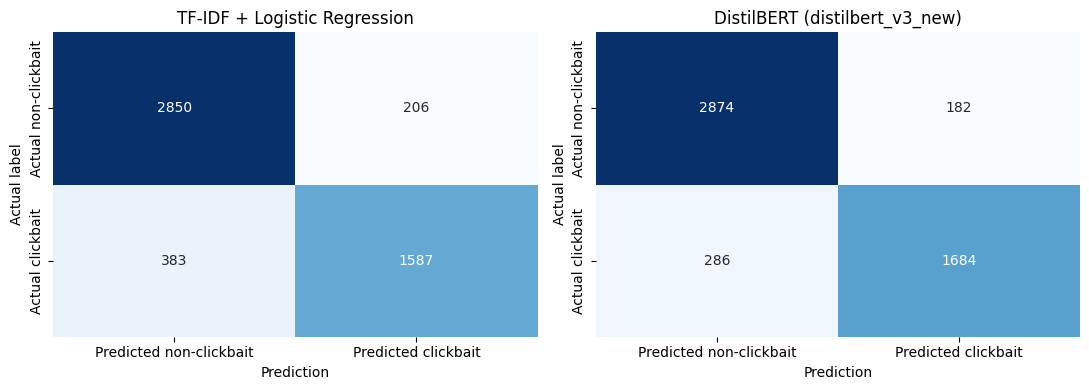


 TF-IDF + Logistic Regression
               precision    recall  f1-score   support

non-clickbait     0.8815    0.9326    0.9063      3056
    clickbait     0.8851    0.8056    0.8435      1970

     accuracy                         0.8828      5026
    macro avg     0.8833    0.8691    0.8749      5026
 weighted avg     0.8829    0.8828    0.8817      5026


 DistilBERT (distilbert_v3_new)
               precision    recall  f1-score   support

non-clickbait     0.9095    0.9404    0.9247      3056
    clickbait     0.9025    0.8548    0.8780      1970

     accuracy                         0.9069      5026
    macro avg     0.9060    0.8976    0.9014      5026
 weighted avg     0.9067    0.9069    0.9064      5026



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, pred in zip(axes, ['TF-IDF + Logistic Regression', f'DistilBERT ({BEST_MODEL_FOLDER})'], [tfidf_pred, bert_pred]):
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Predicted non-clickbait', 'Predicted clickbait'],
                yticklabels=['Actual non-clickbait', 'Actual clickbait'])
    ax.set_title(name)
    ax.set_xlabel('Prediction')
    ax.set_ylabel('Actual label')
plt.tight_layout()
plt.show()

for name, pred in [('TF-IDF + Logistic Regression', tfidf_pred), (f'DistilBERT ({BEST_MODEL_FOLDER})', bert_pred)]:
    print('\n', name)
    print(classification_report(y_true, pred, labels=[0, 1], target_names=['non-clickbait','clickbait'], digits=4, zero_division=0))


## 7. Save final results and error examples
These outputs are saved in Drive under `results/final_test/`. The test set was accessed earlier in the project, so report this as the final evaluation run while noting it was previously inspected.

In [7]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(RESULTS_DIR / 'final_test_metrics.csv', index=False)
predictions = test_df.reset_index(drop=True).copy()
predictions['tfidf_predicted_label'] = tfidf_pred
predictions['tfidf_clickbait_confidence_percent'] = (tfidf_prob * 100).round(2)
predictions['distilbert_predicted_label'] = bert_pred
predictions['distilbert_clickbait_confidence_percent'] = (bert_prob * 100).round(2)
predictions.to_csv(RESULTS_DIR / 'final_test_predictions.csv', index=False, encoding='utf-8-sig')
print('Saved metrics and predictions to:', RESULTS_DIR)


Saved metrics and predictions to: /content/drive/MyDrive/clickbait_project/results/final_test
